In [1]:
!pip install ultralytics

  Using cached numpy-2.5.4-cp314-cp314-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached opencv_python-5.0.0.93-cp37-abi3-macosx_13_0_arm64.whl.metadata (19 kB)
  Using cached pyyaml-6.0.3-cp314-cp314-macosx_11_0_arm64.whl.metadata (2.4 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached torch-2.14.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (39 kB)
  Using cached torchvision-0.29.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (5.7 kB)
  Using cached nvidia_ml_py-13.615.71-py3-none-any.whl.metadata (9.7 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp314-cp314-macosx_10_15_universal2.whl.metadata (137 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.w

In [3]:
!pip install opencv-python


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [5]:
!pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 6.9 MB/s  0:00:02eta 0:00:01

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [7]:
!pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [10]:
!pip install tqdm

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)

[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [11]:
# ==========================================
# Import Required Libraries
# ==========================================

# Standard libraries
import os
import random
from pathlib import Path
from collections import Counter
import shutil

# Numerical computing
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Image processing
import cv2
from PIL import Image

# YOLO (Ultralytics)
from ultralytics import YOLO

# Notebook utilities
from tqdm import tqdm

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

In [14]:
# ==========================================
# Dataset Paths
# ==========================================

DATASET_PATH = "/Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/data/WearHelmetDetection.v1i.yolov8"

TRAIN_IMAGES = os.path.join(DATASET_PATH, "train/images")
TRAIN_LABELS = os.path.join(DATASET_PATH, "train/labels")

VAL_IMAGES = os.path.join(DATASET_PATH, "valid/images")
VAL_LABELS = os.path.join(DATASET_PATH, "valid/labels")

TEST_IMAGES = os.path.join(DATASET_PATH, "test/images")
TEST_LABELS = os.path.join(DATASET_PATH, "test/labels")

# **Dataset Overview**

In [15]:
# ==========================================
# Dataset Overview
# ==========================================

# Count images and labels in each split
train_images = len(os.listdir(TRAIN_IMAGES))
train_labels = len(os.listdir(TRAIN_LABELS))

val_images = len(os.listdir(VAL_IMAGES))
val_labels = len(os.listdir(VAL_LABELS))

test_images = len(os.listdir(TEST_IMAGES))
test_labels = len(os.listdir(TEST_LABELS))

print(f"Train Images : {train_images}")
print(f"Train Labels : {train_labels}")

print(f"\nValidation Images : {val_images}")
print(f"Validation Labels : {val_labels}")

print(f"\nTest Images : {test_images}")
print(f"Test Labels : {test_labels}")

Train Images : 2564
Train Labels : 2564

Validation Images : 986
Validation Labels : 986

Test Images : 394
Test Labels : 394


In [87]:
# ==========================================
# Class Names
# ==========================================

class_names = [
   'Head_without_helmet', 
   'Helmet_only', 
   'Helmet_with_head'
]

print(class_names)

['Head_without_helmet', 'Helmet_only', 'Helmet_with_head']


In [88]:
# ==========================================
# Display Dataset Information
# ==========================================

print("=" * 50)
print("Helmet Wearing Detection Dataset")
print("=" * 50)

print(f"Number of Classes : {len(class_names)}")
print(f"Training Images   : {train_images}")
print(f"Validation Images : {val_images}")
print(f"Test Images       : {test_images}")

print("\nClasses:")
for i, cls in enumerate(class_names):
    print(f"{i} -> {cls}")

Helmet Wearing Detection Dataset
Number of Classes : 3
Training Images   : 2564
Validation Images : 986
Test Images       : 394

Classes:
0 -> Head_without_helmet
1 -> Helmet_only
2 -> Helmet_with_head


# **EDA**

In [89]:
# ==========================================
# Analyze Class Distribution for Train
# ==========================================

# Initialize class counts
class_counts = {i: 0 for i in range(len(class_names))}

# Get all label files
label_files = os.listdir(TRAIN_LABELS)

# Count objects for each class
for label_file in tqdm(label_files):

    label_path = os.path.join(TRAIN_LABELS, label_file)

    with open(label_path, "r") as file:

        lines = file.readlines()

        for line in lines:

            class_id = int(line.split()[0])

            class_counts[class_id] += 1

num_obj = np.sum(list(class_counts.values()))

# Convert to DataFrame
class_df_train = pd.DataFrame({
    "Class": class_names,
    "Objects": list(class_counts.values()),
    'percentage': list(class_counts.values())/num_obj*100
})

class_df_train

  0%|          | 0/2564 [00:00<?, ?it/s]

100%|██████████| 2564/2564 [00:00<00:00, 7739.14it/s]


,Class,Objects,percentage
0,Head_without_helmet,3050,24.932559
1,Helmet_only,317,2.591351
2,Helmet_with_head,8866,72.476089


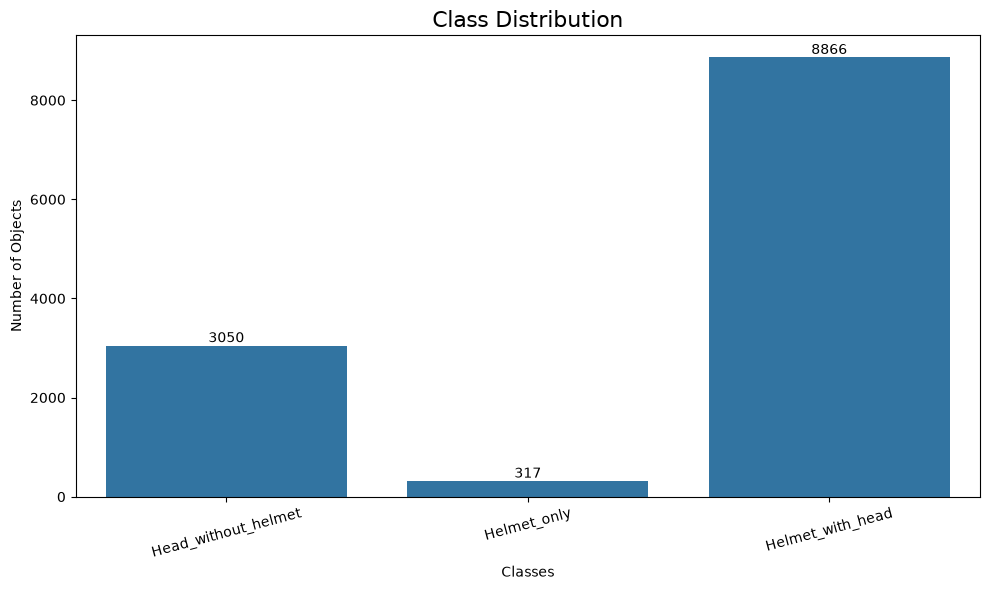

In [90]:
# ==========================================
# Plot Class Distribution
# ==========================================

plt.figure(figsize=(10,6))

bars = sns.barplot(
    x=class_df_train["Class"],
    y=class_df_train["Objects"]
)

plt.title("Class Distribution", fontsize=16)

plt.xlabel("Classes")

plt.ylabel("Number of Objects")

plt.xticks(rotation=15)

# Add values above bars
for i in bars.containers:
    bars.bar_label(i)

plt.tight_layout()

plt.show()

In [91]:
# ==========================================
# Analyze Class Distribution for Validate
# ==========================================

# Initialize class counts
class_counts = {i: 0 for i in range(len(class_names))}

# Get all label files
label_files = os.listdir(VAL_LABELS)

# Count objects for each class
for label_file in tqdm(label_files):

    label_path = os.path.join(VAL_LABELS, label_file)

    with open(label_path, "r") as file:

        lines = file.readlines()

        for line in lines:

            class_id = int(line.split()[0])

            class_counts[class_id] += 1

num_obj = np.sum(list(class_counts.values()))

# Convert to DataFrame
class_df_val = pd.DataFrame({
    "Class": class_names,
    "Objects": list(class_counts.values()),
    'percentage': list(class_counts.values())/num_obj*100
})
class_df_val

100%|██████████| 986/986 [00:00<00:00, 7516.22it/s]


,Class,Objects,percentage
0,Head_without_helmet,1310,27.486362
1,Helmet_only,93,1.951322
2,Helmet_with_head,3363,70.562316


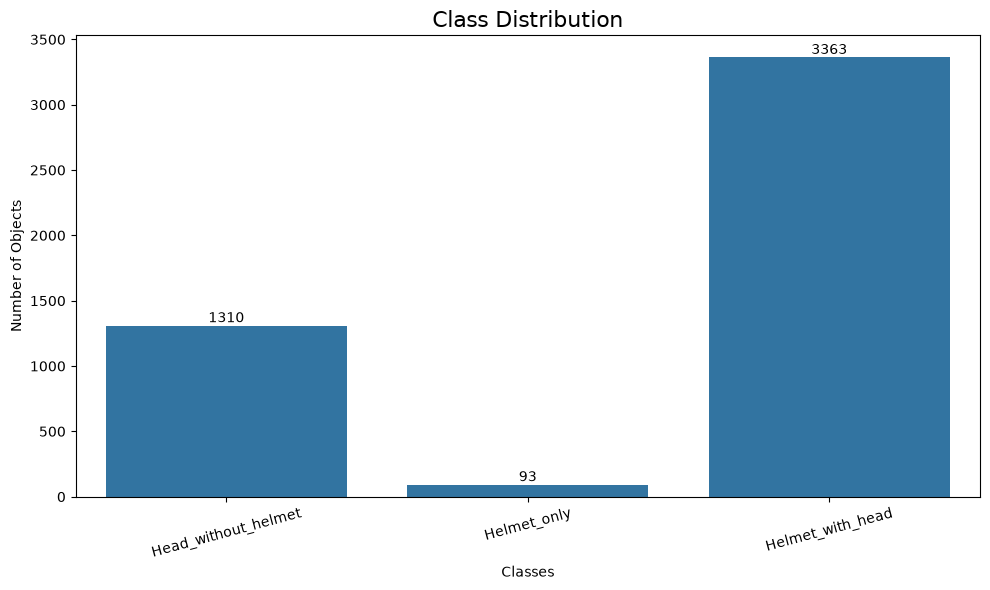

In [92]:
# ==========================================
# Plot Class Distribution
# ==========================================

plt.figure(figsize=(10,6))

bars = sns.barplot(
    x=class_df_val["Class"],
    y=class_df_val["Objects"]
)

plt.title("Class Distribution", fontsize=16)

plt.xlabel("Classes")

plt.ylabel("Number of Objects")

plt.xticks(rotation=15)

# Add values above bars
for i in bars.containers:
    bars.bar_label(i)

plt.tight_layout()

plt.show()

In [93]:
# ==========================================
# Analyze Class Distribution for Test
# ==========================================

# Initialize class counts
class_counts = {i: 0 for i in range(len(class_names))}

# Get all label files
label_files = os.listdir(TEST_LABELS)

# Count objects for each class
for label_file in tqdm(label_files):

    label_path = os.path.join(TEST_LABELS, label_file)

    with open(label_path, "r") as file:

        lines = file.readlines()

        for line in lines:

            class_id = int(line.split()[0])

            class_counts[class_id] += 1

num_obj = np.sum(list(class_counts.values()))

# Convert to DataFrame
class_df_test = pd.DataFrame({
    "Class": class_names,
    "Objects": list(class_counts.values()),
    'percentage': list(class_counts.values())/num_obj*100
})
class_df_test

100%|██████████| 394/394 [00:00<00:00, 7370.41it/s]


,Class,Objects,percentage
0,Head_without_helmet,326,19.439475
1,Helmet_only,34,2.027430
2,Helmet_with_head,1317,78.533095


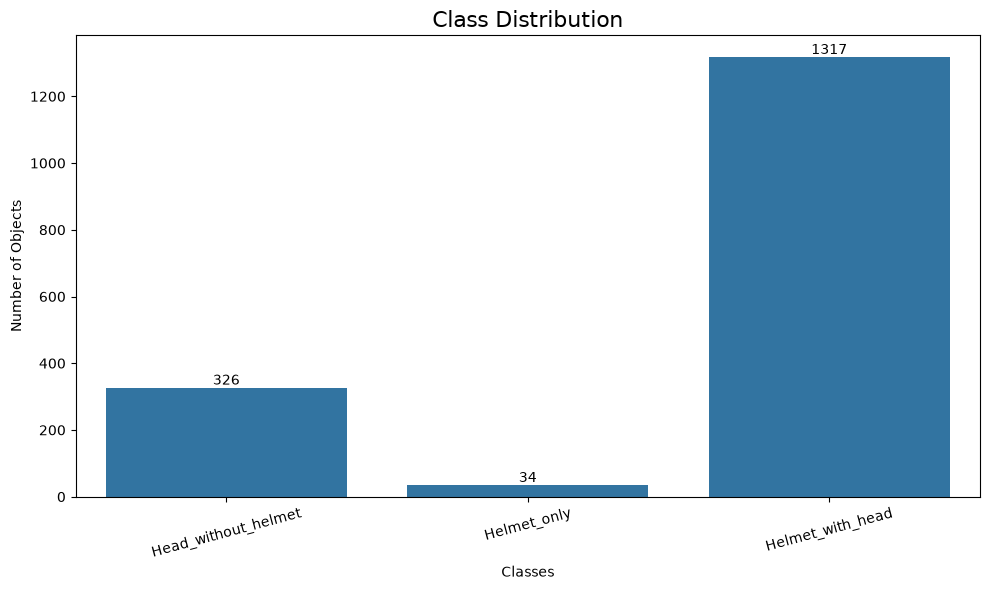

In [94]:
# ==========================================
# Plot Class Distribution
# ==========================================

plt.figure(figsize=(10,6))

bars = sns.barplot(
    x=class_df_test["Class"],
    y=class_df_test["Objects"]
)

plt.title("Class Distribution", fontsize=16)

plt.xlabel("Classes")

plt.ylabel("Number of Objects")

plt.xticks(rotation=15)

# Add values above bars
for i in bars.containers:
    bars.bar_label(i)

plt.tight_layout()

plt.show()

# Observation:
The dataset is moderately imbalanced across the 3 helmet wearing detection. head without helmet is the most frequent class in all dataset splits, while helmet only has the fewest annotated objects. Despite this imbalance, the validation and test sets follow a distribution similar to the training set, indicating that the dataset was split consistently. This consistent distribution provides a reliable basis for model training and evaluation.

In [95]:
# ==========================================
# Objects per Image Analysis
# ==========================================

objects_per_image = []

for label_file in tqdm(os.listdir(TRAIN_LABELS)):

    label_path = os.path.join(TRAIN_LABELS, label_file)

    with open(label_path, "r") as f:

        num_objects = len(f.readlines())

    objects_per_image.append(num_objects)

objects_per_image = np.array(objects_per_image)

100%|██████████| 2564/2564 [00:00<00:00, 6895.87it/s]


In [96]:
# ==========================================
# Objects Statistics
# ==========================================

print(f"Total Images      : {len(objects_per_image)}")
print(f"Total Objects     : {objects_per_image.sum()}")
print(f"Average Objects   : {objects_per_image.mean():.2f}")
print(f"Median Objects    : {np.median(objects_per_image):.2f}")
print(f"Minimum Objects   : {objects_per_image.min()}")
print(f"Maximum Objects   : {objects_per_image.max()}")

Total Images      : 2564
Total Objects     : 12233
Average Objects   : 4.77
Median Objects    : 3.00
Minimum Objects   : 1
Maximum Objects   : 42


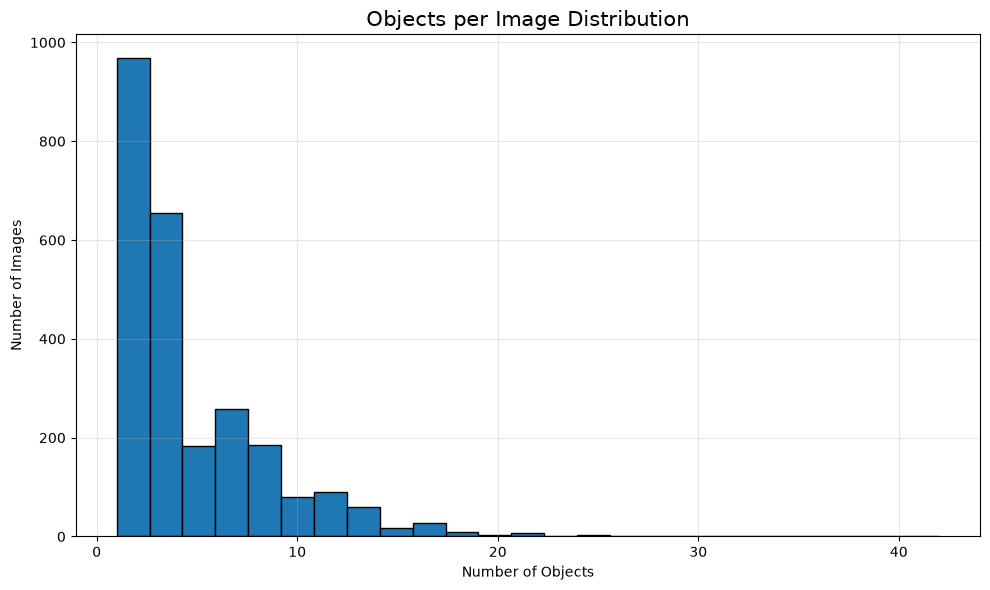

In [97]:
# ==========================================
# Plot Objects per Image
# ==========================================

plt.figure(figsize=(10,6))

plt.hist(
    objects_per_image,
    bins=25,
    edgecolor="black"
)

plt.title("Objects per Image Distribution", fontsize=15)

plt.xlabel("Number of Objects")

plt.ylabel("Number of Images")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

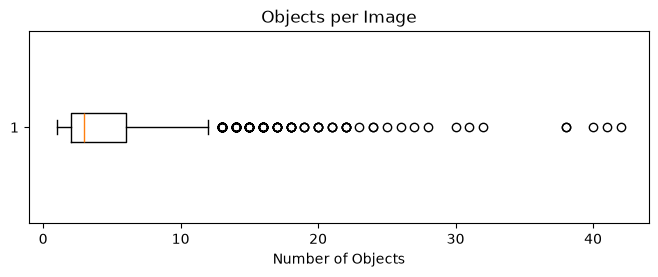

In [98]:
# ==========================================
# Objects per Image Boxplot
# ==========================================

plt.figure(figsize=(8,2.5))

plt.boxplot(
    objects_per_image,
    vert=False
)

plt.title("Objects per Image")

plt.xlabel("Number of Objects")

plt.show()

In [99]:
for i in range(25):
    print(f'{i} --> {(objects_per_image == i).sum()} counts ---> {((objects_per_image == i).sum()/len(objects_per_image)*100).round(3)}%')

0 --> 0 counts ---> 0.0%
1 --> 397 counts ---> 15.484%
2 --> 571 counts ---> 22.27%
3 --> 343 counts ---> 13.378%
4 --> 312 counts ---> 12.168%
5 --> 183 counts ---> 7.137%
6 --> 150 counts ---> 5.85%
7 --> 109 counts ---> 4.251%
8 --> 117 counts ---> 4.563%
9 --> 68 counts ---> 2.652%
10 --> 80 counts ---> 3.12%
11 --> 43 counts ---> 1.677%
12 --> 48 counts ---> 1.872%
13 --> 29 counts ---> 1.131%
14 --> 31 counts ---> 1.209%
15 --> 18 counts ---> 0.702%
16 --> 20 counts ---> 0.78%
17 --> 8 counts ---> 0.312%
18 --> 7 counts ---> 0.273%
19 --> 3 counts ---> 0.117%
20 --> 4 counts ---> 0.156%
21 --> 3 counts ---> 0.117%
22 --> 5 counts ---> 0.195%
23 --> 1 counts ---> 0.039%
24 --> 2 counts ---> 0.078%


# Insight:
Although most images contain only one or two wearing instances, a small subset includes multiple objects. These complex scenes may be more challenging for the detection model due to object density and overlapping not wearing regions.

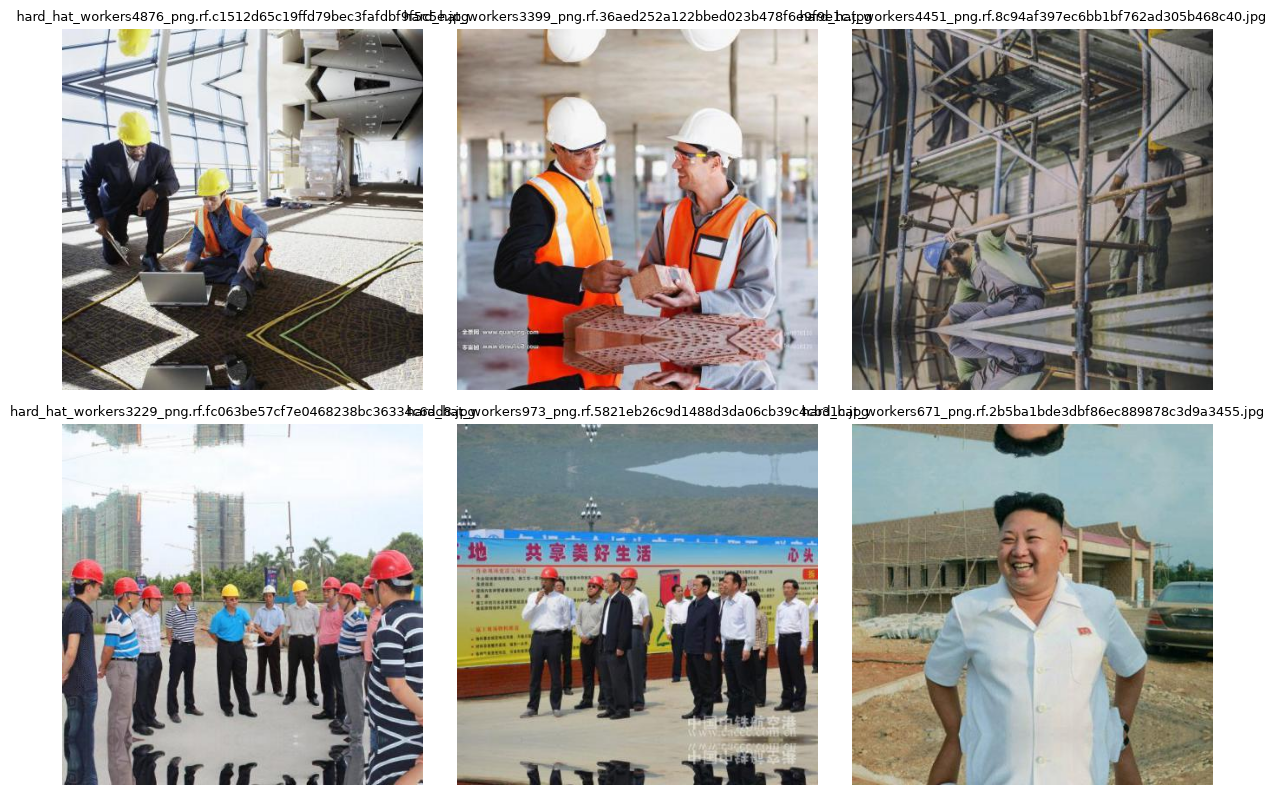

In [100]:
# ==========================================
# Display Random Training Images
# ==========================================

# Get all training images
image_files = os.listdir(TRAIN_IMAGES)

# Select random images
random_images = random.sample(image_files, 6)

plt.figure(figsize=(12, 12))

for i, image_name in enumerate(random_images):

    image_path = os.path.join(TRAIN_IMAGES, image_name)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(image_name, fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [101]:
# ==========================================
# Draw YOLO Bounding Boxes
# ==========================================
def draw_yolo_boxes(image, label_path, class_names=CLASS_NAMES,
                    class_colors=CLASS_COLORS, thickness=2, font_scale=0.6):

    image = image.copy()
    h, w = image.shape[:2]

    if not os.path.exists(label_path):
        return image

    with open(label_path, "r") as file:
        for line in file:
            parts = line.strip().split()
            if len(parts) < 5:          # skip empty / malformed lines
                continue

            class_id = int(float(parts[0]))
            x, y, bw, bh = map(float, parts[1:5])

            if class_id >= len(class_names):
                continue

            name = class_names[class_id]
            color = class_colors.get(name, (255, 255, 255))

            # YOLO (normalized center, w, h) -> pixel corners, clipped to image
            x1 = max(0, int((x - bw / 2) * w))
            y1 = max(0, int((y - bh / 2) * h))
            x2 = min(w - 1, int((x + bw / 2) * w))
            y2 = min(h - 1, int((y + bh / 2) * h))

            # Bounding box
            cv2.rectangle(image, (x1, y1), (x2, y2), color, thickness)

            # Label with filled background
            (tw, th), baseline = cv2.getTextSize(
                name, cv2.FONT_HERSHEY_SIMPLEX, font_scale, 1)
            ty = y1 - 4 if y1 - th - 6 > 0 else y1 + th + 6   # above box, or inside if at top edge
            cv2.rectangle(image, (x1, ty - th - 4), (x1 + tw + 6, ty + baseline - 2),
                          color, -1)
            cv2.putText(image, name, (x1 + 3, ty - 2),
                        cv2.FONT_HERSHEY_SIMPLEX, font_scale,
                        (255, 255, 255), 1, cv2.LINE_AA)

    return image

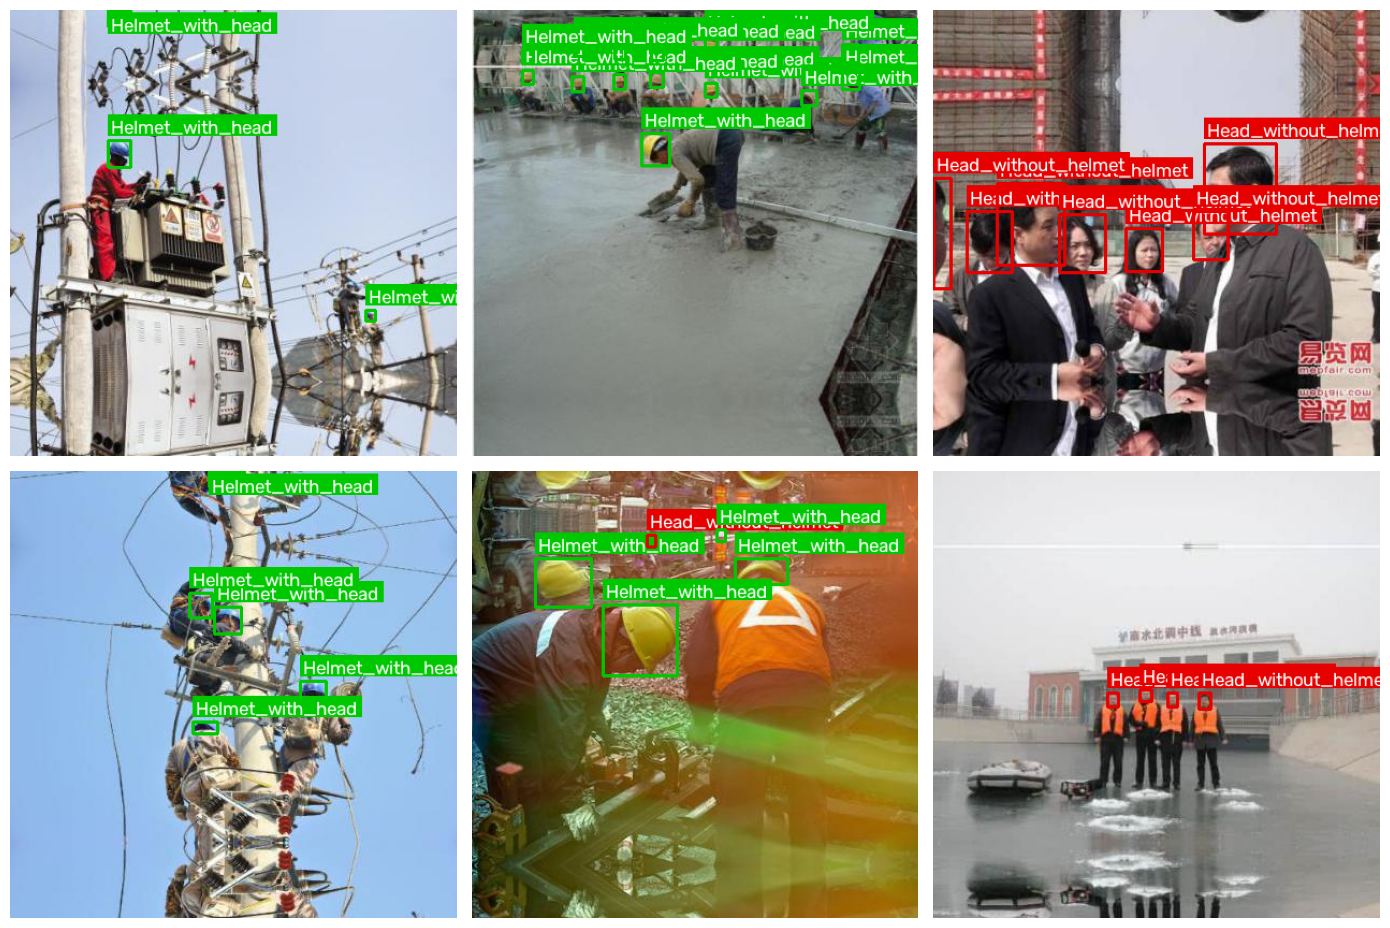

In [103]:
# ==========================================
# Display Random Images with Bounding Boxes
# ==========================================

random_images = random.sample(image_files, 6)

plt.figure(figsize=(14, 14))

for i, image_name in enumerate(random_images):

    image_path = os.path.join(TRAIN_IMAGES, image_name)

    label_name = image_name.replace(".jpg", ".txt")
    label_path = os.path.join(TRAIN_LABELS, label_name)

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    image = draw_yolo_boxes(
        image,
        label_path,
        class_names
    )

    plt.subplot(3,3,i+1)

    plt.imshow(image)

    plt.axis("off")

plt.tight_layout()

plt.show()

# Observation:
The visual inspection confirms that the bounding boxes are correctly aligned with the road damage regions. The dataset contains a wide variety of damage types, object sizes, and road conditions, making it suitable for training robust object detection models.

In [104]:
# ==========================================
# Image Resolution Analysis
# ==========================================

image_widths = []
image_heights = []

sample_images = random.sample(os.listdir(TRAIN_IMAGES), 1000)

for image_name in tqdm(sample_images):

    image_path = os.path.join(TRAIN_IMAGES, image_name)

    with Image.open(image_path) as img:
        width, height = img.size

    image_widths.append(width)
    image_heights.append(height)

100%|██████████| 1000/1000 [00:00<00:00, 4007.79it/s]


In [105]:
# ==========================================
# Image Resolution Statistics
# ==========================================

print(f"Total Images : {len(image_widths)}\n")

print(f"Minimum Width  : {min(image_widths)}")
print(f"Maximum Width  : {max(image_widths)}")
print(f"Average Width  : {np.mean(image_widths):.2f}")

print()

print(f"Minimum Height : {min(image_heights)}")
print(f"Maximum Height : {max(image_heights)}")
print(f"Average Height : {np.mean(image_heights):.2f}")

Total Images : 1000

Minimum Width  : 415
Maximum Width  : 416
Average Width  : 415.93

Minimum Height : 415
Maximum Height : 416
Average Height : 415.49


In [106]:
# ==========================================
# Unique Image Resolutions
# ==========================================

resolution_df = pd.DataFrame({
    "Width": image_widths,
    "Height": image_heights
})

resolution_df["Resolution"] = (
    resolution_df["Width"].astype(str)
    + " × " +
    resolution_df["Height"].astype(str)
)

resolution_df["Resolution"].value_counts()

Resolution
416 × 415    508
416 × 416    422
415 × 416     65
415 × 415      5
Name: count, dtype: int64

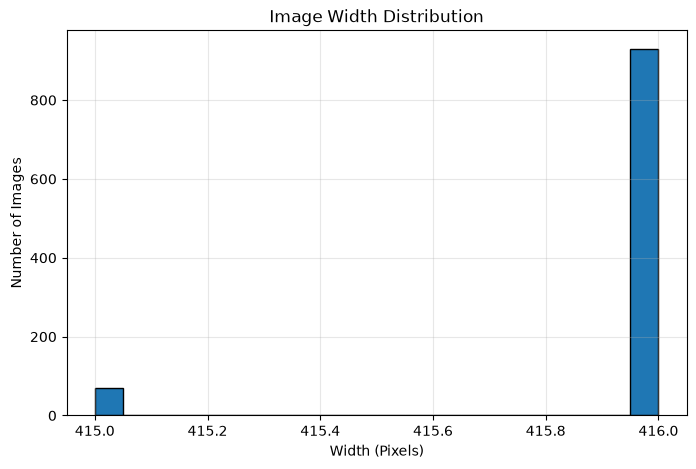

In [107]:
# ==========================================
# Width Distribution
# ==========================================

plt.figure(figsize=(8,5))

plt.hist(
    image_widths,
    bins=20,
    edgecolor="black"
)

plt.title("Image Width Distribution")

plt.xlabel("Width (Pixels)")

plt.ylabel("Number of Images")

plt.grid(alpha=0.3)

plt.show()

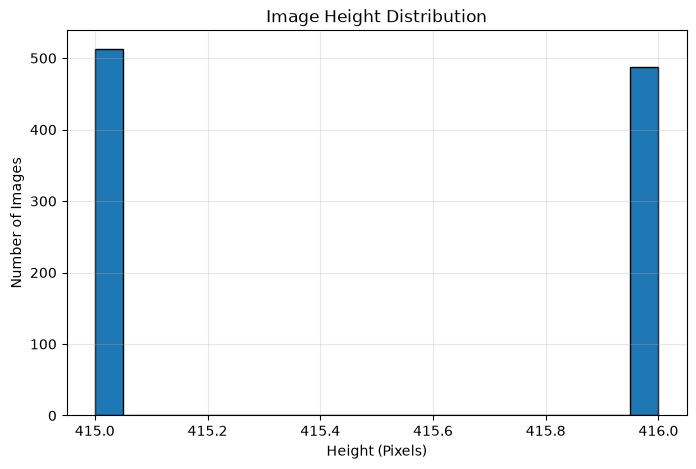

In [108]:
# ==========================================
# Height Distribution
# ==========================================

plt.figure(figsize=(8,5))

plt.hist(
    image_heights,
    bins=20,
    edgecolor="black"
)

plt.title("Image Height Distribution")

plt.xlabel("Height (Pixels)")

plt.ylabel("Number of Images")

plt.grid(alpha=0.3)

plt.show()

# Observation:
A random sample of 1000 training images was analyzed to examine the image resolutions. The dataset contains multiple image sizes, ranging from 512 × 512 to 4040 × 2035 pixels. Most images belong to a few common resolutions, particularly 600 × 600, 720 × 720, and 640 × 640, while high-resolution images (e.g., 4040 × 2035) are less frequent. This variation indicates that the dataset was collected from different cameras and devices. During training, YOLO automatically resizes all images to the selected input size, ensuring a consistent input format for the model.

In [109]:
# ==========================================
# Missing Labels Check
# ==========================================

image_files = {
    os.path.splitext(file)[0]
    for file in os.listdir(TRAIN_IMAGES)
}

label_files = {
    os.path.splitext(file)[0]
    for file in os.listdir(TRAIN_LABELS)
}

missing_labels = image_files - label_files
missing_images = label_files - image_files

print("=" * 50)
print("Missing Labels Check")
print("=" * 50)

print(f"Images without labels : {len(missing_labels)}")
print(f"Labels without images : {len(missing_images)}")

Missing Labels Check
Images without labels : 0
Labels without images : 0


# **Choose sample of data**

In [110]:
# ==========================================
# Build Image Metadata
# ==========================================

records = []

for label_file in os.listdir(TRAIN_LABELS):

    label_path = os.path.join(TRAIN_LABELS, label_file)

    classes = []

    with open(label_path, "r") as f:

        for line in f.readlines():

            class_id = int(line.split()[0])

            classes.append(class_id)

    records.append({

        "image": label_file.replace(".txt", ".jpg"),

        "label": label_file,

        "num_objects": len(classes),

        "classes": classes

    })

train_df = pd.DataFrame(records)

train_df.head()

,image,label,num_objects,classes
0,hard_hat_workers1228_png.rf.f71fcdf697f98ddc0f...,hard_hat_workers1228_png.rf.f71fcdf697f98ddc0f...,2,"[2, 2]"
1,hard_hat_workers29_png.rf.831336e04640d6100ef3...,hard_hat_workers29_png.rf.831336e04640d6100ef3...,5,"[2, 2, 2, 2, 2]"
2,hard_hat_workers3147_png.rf.0a756701ed85f51f17...,hard_hat_workers3147_png.rf.0a756701ed85f51f17...,1,[2]
3,hard_hat_workers1166_png.rf.b15ef08e6e18fea89e...,hard_hat_workers1166_png.rf.b15ef08e6e18fea89e...,3,"[2, 2, 2]"
4,hard_hat_workers1240_png.rf.23444fe63a0d20aa0f...,hard_hat_workers1240_png.rf.23444fe63a0d20aa0f...,10,"[0, 2, 0, 0, 0, 0, 2, 0, 0, 0]"


In [111]:
# ==========================================
# Build Image Metadata
# ==========================================
records = []

for label_file in os.listdir(VAL_LABELS):

    label_path = os.path.join(VAL_LABELS, label_file)

    classes = []

    with open(label_path, "r") as f:

        for line in f.readlines():

            class_id = int(line.split()[0])

            classes.append(class_id)

    records.append({

        "image": label_file.replace(".txt", ".jpg"),

        "label": label_file,

        "num_objects": len(classes),

        "classes": classes

    })

val_df = pd.DataFrame(records)

val_df.head()

,image,label,num_objects,classes
0,hard_hat_workers2126_png.rf.5d421e2c076361544b...,hard_hat_workers2126_png.rf.5d421e2c076361544b...,11,"[2, 2, 2, 2, 2, 0, 0, 0, 0, 0, 0]"
1,hard_hat_workers522_png.rf.ea5edb6f7de8f359cda...,hard_hat_workers522_png.rf.ea5edb6f7de8f359cda...,7,"[0, 0, 0, 0, 0, 0, 0]"
2,hard_hat_workers4913_png.rf.2916079371daba5256...,hard_hat_workers4913_png.rf.2916079371daba5256...,5,"[2, 2, 2, 2, 0]"
3,hard_hat_workers3274_png.rf.2705647fd681ed7b3c...,hard_hat_workers3274_png.rf.2705647fd681ed7b3c...,6,"[2, 2, 2, 2, 2, 2]"
4,hard_hat_workers4498_png.rf.d2b5bf51fcbf6e0bf6...,hard_hat_workers4498_png.rf.d2b5bf51fcbf6e0bf6...,2,"[2, 2]"


In [112]:
# ==========================================
# Build Image Metadata
# ==========================================

records = []

for label_file in os.listdir(TEST_LABELS):

    label_path = os.path.join(TEST_LABELS, label_file)

    classes = []

    with open(label_path, "r") as f:

        for line in f.readlines():

            class_id = int(line.split()[0])

            classes.append(class_id)

    records.append({

        "image": label_file.replace(".txt", ".jpg"),

        "label": label_file,

        "num_objects": len(classes),

        "classes": classes

    })

test_df = pd.DataFrame(records)

test_df.head()

,image,label,num_objects,classes
0,hard_hat_workers3542_png.rf.6343748e750959c0df...,hard_hat_workers3542_png.rf.6343748e750959c0df...,1,[2]
1,hard_hat_workers2735_png.rf.1518fd8569d7b35a2f...,hard_hat_workers2735_png.rf.1518fd8569d7b35a2f...,2,"[2, 2]"
2,hard_hat_workers388_png.rf.2d10af3d01c6a27122a...,hard_hat_workers388_png.rf.2d10af3d01c6a27122a...,6,"[2, 2, 2, 2, 1, 2]"
3,hard_hat_workers4862_png.rf.da394fd733670ced4a...,hard_hat_workers4862_png.rf.da394fd733670ced4a...,5,"[2, 2, 2, 2, 2]"
4,hard_hat_workers2350_png.rf.3f1f9a079926872038...,hard_hat_workers2350_png.rf.3f1f9a079926872038...,6,"[2, 2, 2, 2, 2, 2]"


In [113]:
def calculate_class_distribution(df):

    counter = Counter()

    for classes in df["classes"]:
        counter.update(classes)

    total = sum(counter.values())

    distribution = pd.DataFrame({
        "Class": list(counter.keys()),
        "Objects": list(counter.values())
    })

    distribution["Percentage"] = (
        distribution["Objects"] / total * 100
    )

    return distribution.sort_values("Class").reset_index(drop=True)

In [114]:
train_sample = train_df.sample(
    n=1000,
    random_state=42
)

train_sample_distribution = calculate_class_distribution(train_sample)

train_sample_distribution

,Class,Objects,Percentage
0,0,1114,23.467453
1,1,130,2.738572
2,2,3503,73.793975


In [115]:
class_df_train

,Class,Objects,percentage
0,Head_without_helmet,3050,24.932559
1,Helmet_only,317,2.591351
2,Helmet_with_head,8866,72.476089


In [116]:
val_sample = val_df.sample(
    n=200,
    random_state=42
)

val_sample_distribution = calculate_class_distribution(val_sample)

val_sample_distribution

,Class,Objects,Percentage
0,0,248,25.514403
1,1,22,2.263374
2,2,702,72.222222


In [117]:
class_df_val

,Class,Objects,percentage
0,Head_without_helmet,1310,27.486362
1,Helmet_only,93,1.951322
2,Helmet_with_head,3363,70.562316


In [118]:
test_sample = test_df.sample(
    n=200,
    random_state=42
)

test_sample_distribution = calculate_class_distribution(test_sample)

test_sample_distribution

,Class,Objects,Percentage
0,0,171,18.627451
1,1,16,1.742919
2,2,731,79.629630


In [119]:
class_df_test

,Class,Objects,percentage
0,Head_without_helmet,326,19.439475
1,Helmet_only,34,2.027430
2,Helmet_with_head,1317,78.533095


# Observation:
A random subset of the training dataset was selected using a fixed random seed (random_state=42). After comparing the class distribution between the original dataset and the sampled dataset, the differences across all classes were found to be less than 0.5%, indicating that the sampled dataset preserves the original class distribution and can be considered representative for model training and evaluation.

In [ ]:
# ==========================================
# Create HWD_SAMPLE Directory Structure
# ==========================================

import os

BASE_SAMPLE_DIR = "/Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/data/HWD_SAMPLE"

splits = ["train", "val", "test"]
folders = ["images", "labels"]

for split in splits:
    for folder in folders:

        os.makedirs(
            os.path.join(BASE_SAMPLE_DIR, split, folder),
            exist_ok=True
        )

print("RDD_SAMPLE directory created successfully!")

RDD_SAMPLE directory created successfully!


In [51]:
# ==========================================
# Copy Sample Dataset
# ==========================================

def copy_sample(df,
                source_images,
                source_labels,
                destination):

    for _, row in tqdm(df.iterrows(), total=len(df)):

        # Image
        shutil.copy2(
            os.path.join(source_images, row["image"]),
            os.path.join(destination, "images", row["image"])
        )

        # Label
        shutil.copy2(
            os.path.join(source_labels, row["label"]),
            os.path.join(destination, "labels", row["label"])
        )

In [52]:
copy_sample(
    train_sample,
    TRAIN_IMAGES,
    TRAIN_LABELS,
    os.path.join(BASE_SAMPLE_DIR, "train")
)

100%|██████████| 1000/1000 [00:00<00:00, 1232.01it/s]


In [53]:
copy_sample(
    val_sample,
    VAL_IMAGES,
    VAL_LABELS,
    os.path.join(BASE_SAMPLE_DIR, "val")
)

100%|██████████| 200/200 [00:00<00:00, 1170.49it/s]


In [54]:
copy_sample(
    test_sample,
    TEST_IMAGES,
    TEST_LABELS,
    os.path.join(BASE_SAMPLE_DIR, "test")
)

100%|██████████| 200/200 [00:00<00:00, 1288.37it/s]


In [120]:
# ==========================================
# Verify Sample Dataset
# ==========================================

for split in splits:

    image_count = len(os.listdir(os.path.join(BASE_SAMPLE_DIR, split, "images")))

    label_count = len(os.listdir(os.path.join(BASE_SAMPLE_DIR, split, "labels")))

    print(f"{split.upper()}")

    print(f"Images : {image_count}")

    print(f"Labels : {label_count}")

    print("-"*30)

TRAIN
Images : 1000
Labels : 1000
------------------------------
VAL
Images : 200
Labels : 200
------------------------------
TEST
Images : 200
Labels : 200
------------------------------


# **Create data.yaml**

In [121]:
# ==========================================
# Create data.yaml
# ==========================================

data_yaml = """

train: /Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/data/HWD_SAMPLE/train/images
val: /Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/data/HWD_SAMPLE/val/images
test: /Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/data/HWD_SAMPLE/test/images

nc: 3

names:
  0: Head_without_helmet
  1: Helmet_only
  2: Helmet_with_head
"""

with open("data.yaml", "w") as f:
    f.write(data_yaml)

print("data.yaml created successfully!")

data.yaml created successfully!


In [122]:
with open('/Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/notebook/data.yaml','r') as y:
    print(y.read())




train: /Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/data/HWD_SAMPLE/train/images
val: /Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/data/HWD_SAMPLE/val/images
test: /Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/data/HWD_SAMPLE/test/images

nc: 3

names:
  0: Head_without_helmet
  1: Helmet_only
  2: Helmet_with_head



# **YOLOv8 Small**

In [58]:
# ==========================================
# Load YOLOv8 Small Model
# ==========================================
from ultralytics import YOLO
model_small = YOLO("yolov8s.pt")

In [123]:
# ==========================================
# Train YOLOv8 Small Model
# ==========================================
PROJECT_ROOT = "users/sandrakhyikwa/AI_Tech/helmet-wearing-detection"
results_small = model_small.train(

    data=f"/Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/notebook/data.yaml",

    epochs=10,

    imgsz=640,

    batch=16,

    patience=20,

    seed=42,

    project=f"/Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/reports/runs/detect",

    name="YOLOv8s",

    device="mps",
    
    exist_ok=True,
)

Ultralytics 8.4.189 🚀 Python-3.14.0 torch-2.14.1 MPS (Apple M4)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/notebook/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/reports/runs/detect/YOLOv8s/weights/best.pt

In [124]:
# ==========================================
# Read Training Results
# ==========================================

results = pd.read_csv(
    "/Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/reports/runs/detect/YOLOv8s/results.csv"
)

results

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,103.134,0.85827,1.50969,0.91368,0.52729,0.59412,0.56287,0.40428,0.97516,0.98988,0.99378,0.000469,0.000469,0.000469
1,2,188.950,0.88329,0.73705,0.94288,0.59358,0.61504,0.59861,0.42614,0.99404,0.87495,1.03512,0.000852,0.000852,0.000852
2,3,282.538,0.93215,0.69209,0.95836,0.68782,0.59885,0.64822,0.47837,1.01212,0.86197,1.02729,0.001140,0.001140,0.001140
3,4,372.046,0.95093,0.67722,0.97407,0.54485,0.65716,0.59900,0.44317,0.96899,0.89152,1.01221,0.001005,0.001005,0.001005
4,5,460.742,0.92843,0.63483,0.95242,0.64703,0.68952,0.63899,0.46637,1.01674,0.80602,1.01915,0.000863,0.000863,0.000863
5,6,552.515,0.90430,0.60120,0.94111,0.54740,0.73978,0.64088,0.46960,0.96935,0.72858,0.99474,0.000722,0.000722,0.000722
6,7,639.193,0.88700,0.55434,0.93391,0.67037,0.77802,0.68278,0.50540,0.96626,0.70651,0.99616,0.000580,0.000580,0.000580
7,8,731.229,0.86863,0.54227,0.92540,0.63105,0.72643,0.68723,0.51846,0.93170,0.66800,0.97364,0.000439,0.000439,0.000439
8,9,825.105,0.84061,0.51027,0.91337,0.70628,0.71971,0.70662,0.53143,0.91841,0.64647,0.97405,0.000297,0.000297,0.000297
9,10,910.714,0.83147,0.49362,0.91452,0.72583,0.71891,0.71247,0.54831,0.90299,0.60536,0.96677,0.000156,0.000156,0.000156


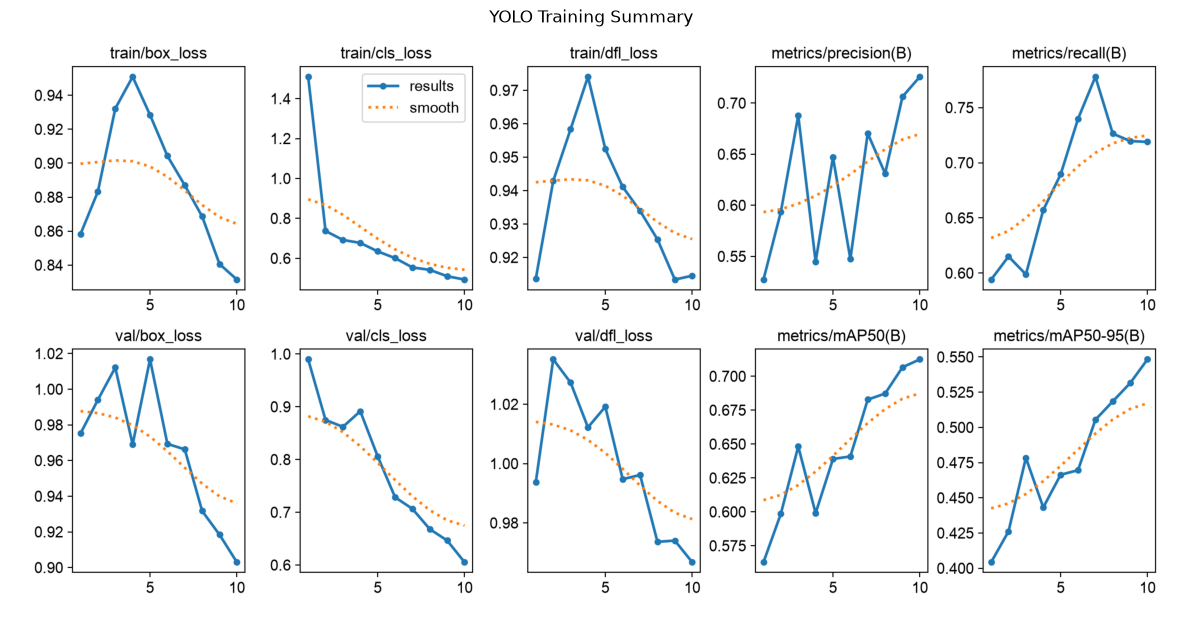

In [125]:
img_path = '/Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/reports/runs/detect/YOLOv8s/results.png'
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15,8))
plt.imshow(img)
plt.axis("off")
plt.title("YOLO Training Summary")
plt.show()

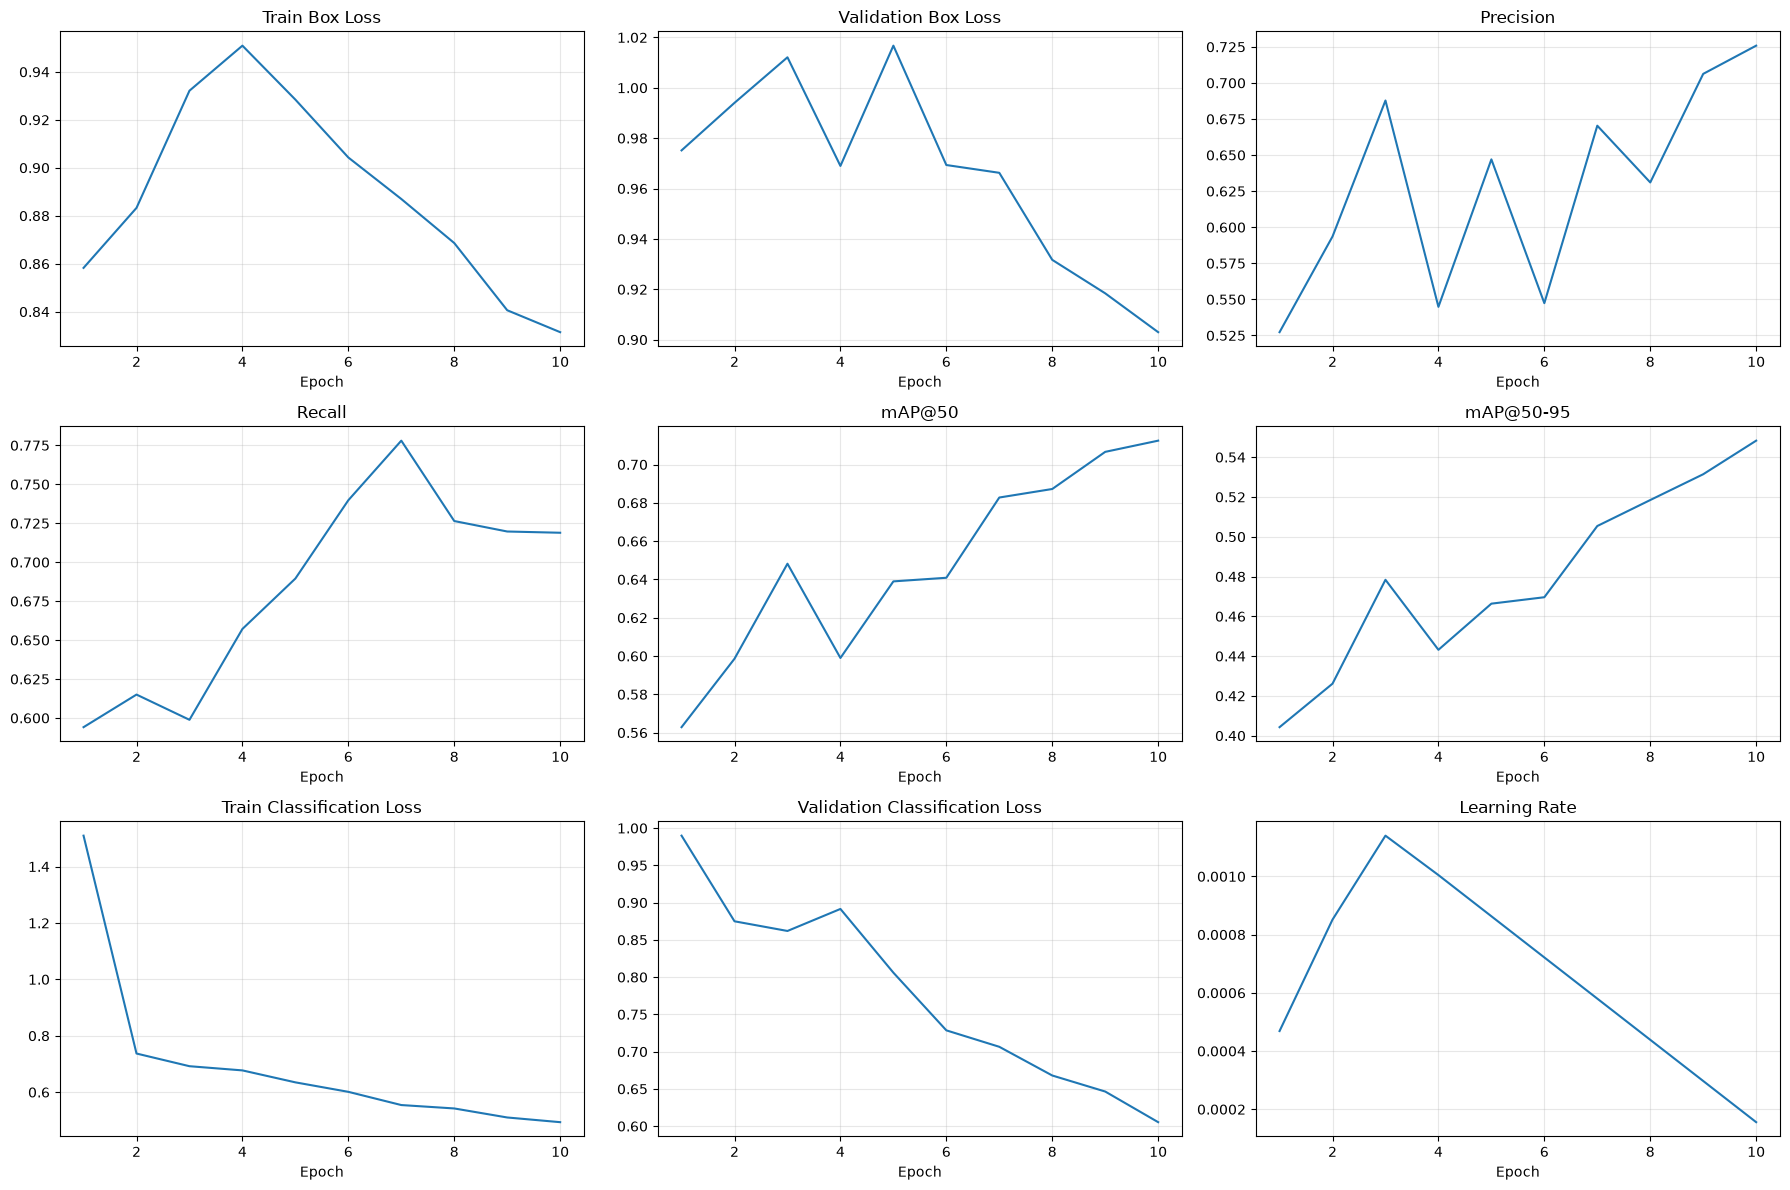

In [126]:
# ==========================================
# Visualize Training Results
# ==========================================

metrics = [

    ("train/box_loss", "Train Box Loss"),

    ("val/box_loss", "Validation Box Loss"),

    ("metrics/precision(B)", "Precision"),

    ("metrics/recall(B)", "Recall"),

    ("metrics/mAP50(B)", "mAP@50"),

    ("metrics/mAP50-95(B)", "mAP@50-95"),

    ("train/cls_loss", "Train Classification Loss"),

    ("val/cls_loss", "Validation Classification Loss"),

    ("lr/pg0", "Learning Rate")

]

plt.figure(figsize=(18, 12))

for i, (column, title) in enumerate(metrics):

    plt.subplot(3, 3, i + 1)

    plt.plot(results["epoch"], results[column])

    plt.title(title)

    plt.xlabel("Epoch")

    plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

In [127]:
best_model_small = YOLO(
    "/Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/reports/runs/detect/YOLOv8s/weights/best.pt"
)

# ==========================================
# Evaluate YOLOv8 small Model
# ==========================================

metrics_small = best_model_small.val(
    data=f"/Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/notebook/data.yaml",
    project=f"/Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/reports/runs/detect",
    split="test"
)

Ultralytics 8.4.189 🚀 Python-3.14.0 torch-2.14.1 CPU (Apple M4)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.1 ms, read: 110.9±65.2 MB/s, size: 31.8 KB)
val: Scanning /Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/data/HWD_SAMPLE/test/labels.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 25.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.2s/it 16.0s1.2s
                   all        200        918      0.767       0.75      0.774      0.601
   Head_without_helmet         42        171       0.87      0.819      0.863      0.651
           Helmet_only         13         16      0.514      0.562      0.512      0.428
      Helmet_with_head        185        731      0.919      0.868      0.948      0.724
Speed: 1.0ms preprocess, 75.5ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to 

In [128]:
# ==========================================
# Store Evaluation Metrics
# ==========================================

small_results = {

    "Model": "YOLOv8s",

    "Precision": metrics_small.box.mp,

    "Recall": metrics_small.box.mr,

    "mAP50": metrics_small.box.map50,

    "mAP50-95": metrics_small.box.map,

    "FPS": None,

    "Inference Time (ms)": None,

    "Model Size (MB)": round(
        os.path.getsize(
            f"/Users/sandrakhyikwa/AI_Tech/Helmet-wearing-detection/reports/runs/detect/YOLOv8s/weights/best.pt"
        ) / (1024 ** 2),
        2
    )

}
small_results

{'Model': 'YOLOv8s',
 'Precision': np.float64(0.7674720127795288),
 'Recall': np.float64(0.7501443934267206),
 'mAP50': np.float64(0.7744422043421748),
 'mAP50-95': np.float64(0.6008431708612588),
 'FPS': None,
 'Inference Time (ms)': None,
 'Model Size (MB)': 21.47}

In [129]:
# ==========================================
# Select Random Test Images
# ==========================================

sample_images = np.random.choice(
    os.listdir(TEST_IMAGES),
    6
)

sample_images

array(['hard_hat_workers1116_png.rf.7cc65945da90d7396b636cd982363c8a.jpg', 'hard_hat_workers1824_png.rf.076b1e03f524e426a58fbb7ce8da371c.jpg', 'hard_hat_workers2515_png.rf.650678fac786fa1daa6ae968965facb4.jpg', 'hard_hat_workers1330_png.rf.771fc989c88fe9e27fa5979196be7f7f.jpg',
       'hard_hat_workers2527_png.rf.2ef5abd04388d42a58c4fa2bf6b13a21.jpg', 'hard_hat_workers1621_png.rf.bb1c7b96c1c28b93e01eb26d08935d61.jpg'], dtype='<U64')

In [130]:
sources=[
        os.path.join(TEST_IMAGES, image)
        for image in sample_images]

In [131]:
# ==========================================
# Predict on Test Images
# ==========================================

results = best_model_small.predict(

    source=sources,

    conf=0.25,

    verbose=False
)


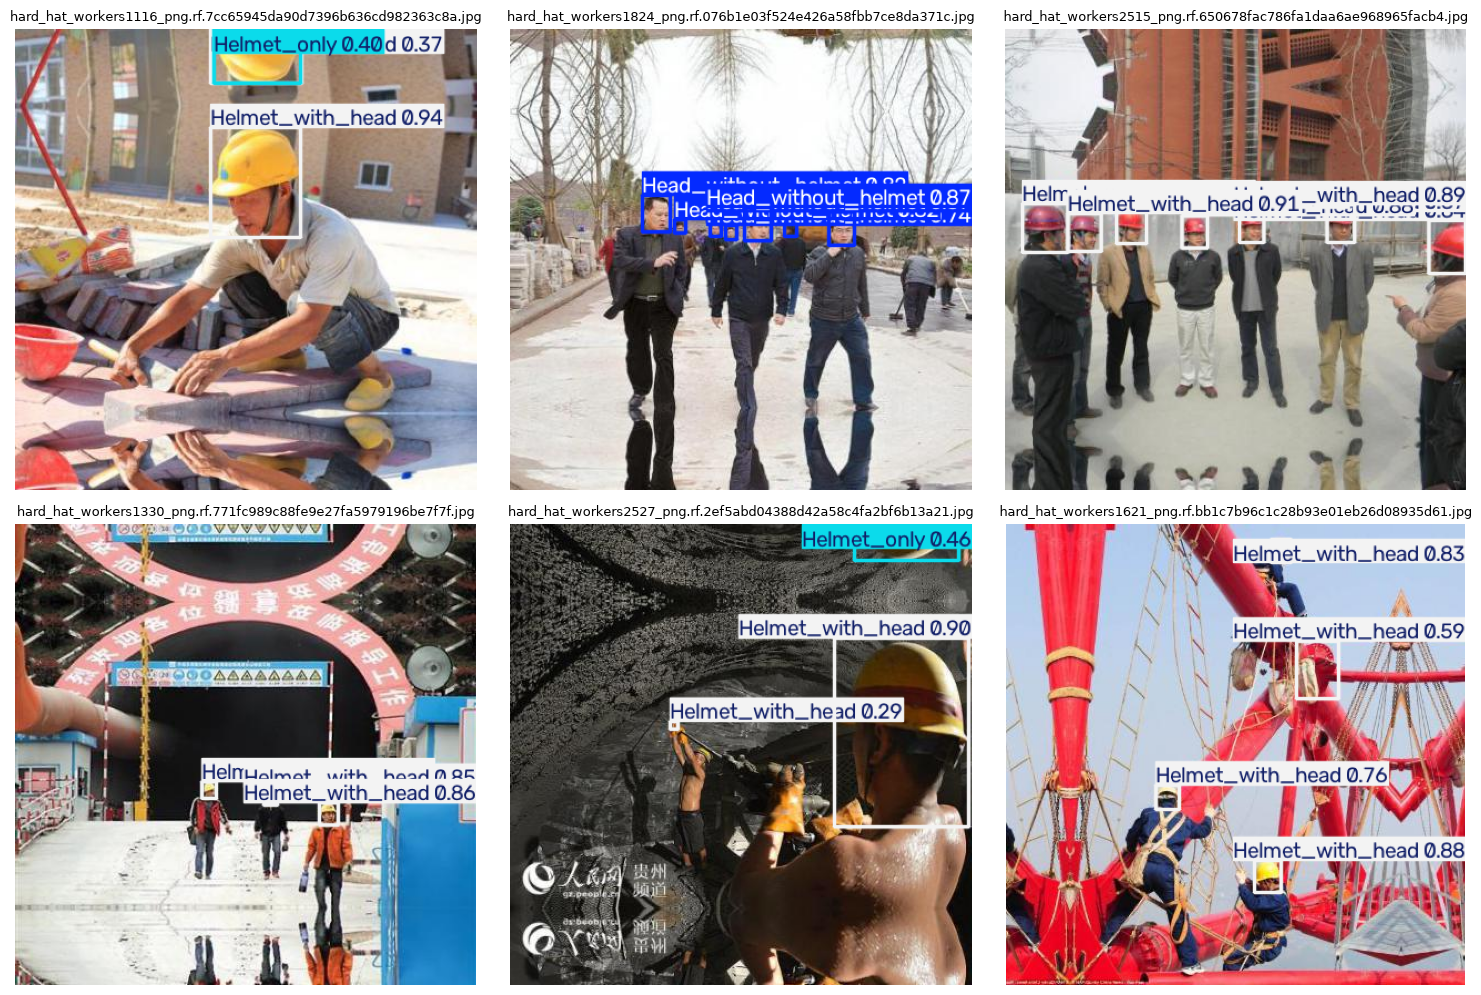

In [132]:
# ==========================================
# Visualize Predictions
# ==========================================

plt.figure(figsize=(15, 15))

for i, result in enumerate(results):

    image = result.plot()

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(3, 3, i + 1)

    plt.imshow(image)

    plt.title(sample_images[i], fontsize=9)

    plt.axis("off")

plt.tight_layout()

plt.show()